# Análisis de Componentes Principales (PCA) de Vuelos

## 1. Carga de Datos y Preprocesamiento

Esta sección carga los datos del archivo CSV 'Vuelos.csv', selecciona las características relevantes, convierte variables categóricas a numéricas y estandariza los datos para prepararlos para el análisis PCA.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

# Cargar datos
ruta = '/content/drive/MyDrive/TpCienciaDatos/'

df = pd.read_csv(ruta + 'Clientes_Demorados_SinDuplicados.csv', sep=';',encoding='latin1')

print("Columnas disponibles en el DataFrame de Clientes:")
print(df.columns)
display(df.head())

# Variables numéricas para PCA
numerical_features = [
    'edad',
    'cant_vuelos',
    'gasto_acumulado',
    'gasto_acumulado_extra',
    'cantidad_millas',
    'ingreso_mensual',
    'anticipacion_compra_promedio'
]

# Seleccionar únicamente variables numéricas
x = df[numerical_features].values

# Estandarizar datos
x_scaled = StandardScaler().fit_transform(x)

print(f"\nSe han seleccionado {len(numerical_features)} características para PCA:")
print(numerical_features)
print("Datos estandarizados (primeras 5 filas):\n", x_scaled[:5])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Columnas disponibles en el DataFrame de Clientes:
Index(['id_cliente', 'sexo', 'provincia', 'edad', 'ocupacion', 'cant_vuelos',
       'clase_preferida', 'gasto_acumulado', 'gasto_acumulado_extra',
       'programaMillas', 'cantidad_millas', 'ingreso_mensual',
       'anticipacion_compra_promedio', 'canal_compra'],
      dtype='object')


,id_cliente,sexo,provincia,edad,ocupacion,cant_vuelos,clase_preferida,gasto_acumulado,gasto_acumulado_extra,programaMillas,cantidad_millas,ingreso_mensual,anticipacion_compra_promedio,canal_compra
0,13492,M,Bolívar,18,Estudiante,7,Económica,1989.84,299.29,Sí,6958,423,69,Web
1,36416,M,CABA,37,Empleado,21,Ejecutiva,12755.43,636.72,No,0,1274,3,App
2,46825,F,Chiriquí,31,Empleado,15,Económica,1831.81,78.85,Sí,7674,1504,24,Agencia
3,21748,F,Pernambuco,55,Ingeniero,23,Ejecutiva,10006.33,2076.95,No,0,4886,44,Web
4,29706,M,Nariño,39,Comerciante,20,Económica,3712.35,696.16,No,0,2780,7,Agencia



Se han seleccionado 7 características para PCA:
['edad', 'cant_vuelos', 'gasto_acumulado', 'gasto_acumulado_extra', 'cantidad_millas', 'ingreso_mensual', 'anticipacion_compra_promedio']
Datos estandarizados (primeras 5 filas):
 [[-1.72691207 -0.63819905 -0.37351918 -0.33522382  0.00438911 -0.63705402
   2.29520336]
 [-0.06659547  0.24957418  0.49565194 -0.16242153 -0.28903608 -0.43244438
  -0.79308054]
 [-0.59090597 -0.13090006 -0.38627789 -0.44811402  0.03458348 -0.37714448
   0.18955525]
 [ 1.50633605  0.37639892  0.27370049  0.57513901 -0.28903608  0.4360045
   1.12539885]
 [ 0.1081747   0.1861618  -0.23445054 -0.13198153 -0.28903608 -0.07035025
  -0.60591182]]


## 2. Aplicación de PCA y Análisis de Varianza

Aquí aplicamos el PCA a los datos estandarizados. Luego, visualizamos la varianza acumulada para determinar el número óptimo de componentes principales. También mostraremos los autovalores y la varianza explicada por cada componente.

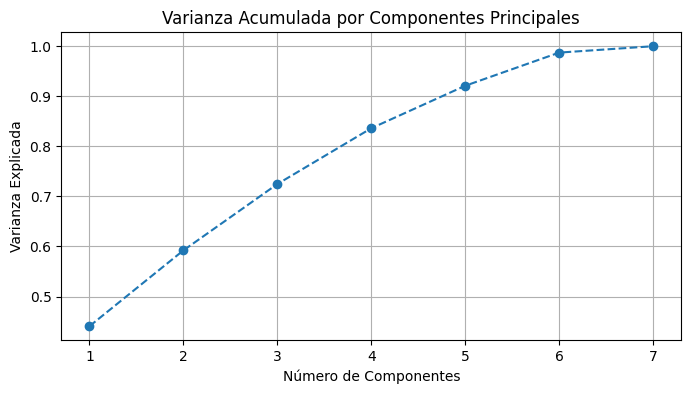

In [ ]:
# Aplicar PCA
pca = PCA()
pca.fit(x_scaled)

# Graficar el Codo (Scree Plot)
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--')
plt.title('Varianza Acumulada por Componentes Principales')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada')
plt.grid(True)
plt.show()

In [ ]:
# Calcular y mostrar los autovalores (eigenvalues)
eigenvalues = pca.explained_variance_
print("Autovalores (Eigenvalues):")
print(eigenvalues)

Autovalores (Eigenvalues):
[3.08536569 1.06026786 0.9274304  0.78031251 0.59397943 0.46371027
 0.08924648]


In [ ]:
# VARIANZA DE CADA COMPONENTE PORCENTUALMENTE: VAR(CPi)/ VARIANZA TOTAL
df_varianza_ratio = pd.DataFrame(data={'Componente': range(1, len(pca.explained_variance_ratio_) + 1), '% Varianza explicada': pca.explained_variance_ratio_})
df_varianza_ratio

,Componente,% Varianza explicada
0,1,0.440747
1,2,0.151460
2,3,0.132484
3,4,0.111468
4,5,0.084850
5,6,0.066241
6,7,0.012749


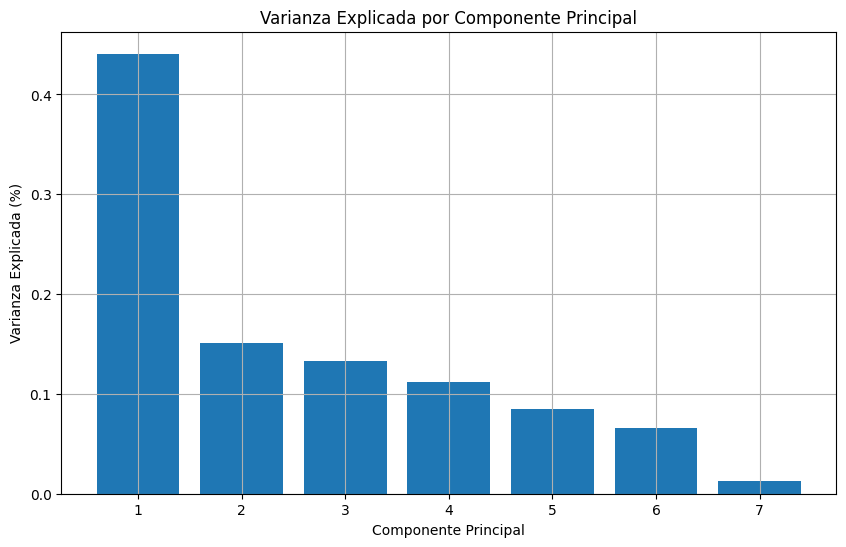

In [ ]:
# Graficar la varianza explicada por cada componente
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_)
plt.xlabel('Componente Principal')
plt.ylabel('Varianza Explicada (%)')
plt.title('Varianza Explicada por Componente Principal')
plt.grid(True)
plt.show()

## 3. Análisis de Loadings y Visualización de Componentes

Esta sección examina los 'loadings' para entender cómo cada variable original contribuye a los componentes principales. Finalmente, visualizamos los datos transformados en el espacio de los dos primeros componentes principales.

In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(numerical_features))],
    index=numerical_features
)

print(loadings)

                                   PC1       PC2       PC3       PC4  \
edad                          0.079050  0.709684  0.674525 -0.163810   
cant_vuelos                   0.446510  0.032922 -0.015300 -0.187710   
gasto_acumulado               0.522895 -0.093759 -0.009573 -0.084785   
gasto_acumulado_extra         0.503541 -0.106640 -0.011264 -0.091135   
cantidad_millas               0.406249 -0.093378 -0.052730 -0.254900   
ingreso_mensual               0.309982  0.051262  0.138396  0.924681   
anticipacion_compra_promedio -0.079248 -0.680995  0.722931 -0.049284   

                                   PC5       PC6       PC7  
edad                         -0.011176 -0.090284 -0.002457  
cant_vuelos                   0.152356  0.858744 -0.058503  
gasto_acumulado              -0.364210 -0.171929  0.740474  
gasto_acumulado_extra        -0.472650 -0.239487 -0.667750  
cantidad_millas               0.770344 -0.403943 -0.043458  
ingreso_mensual               0.162737  0.011066 -0.02212

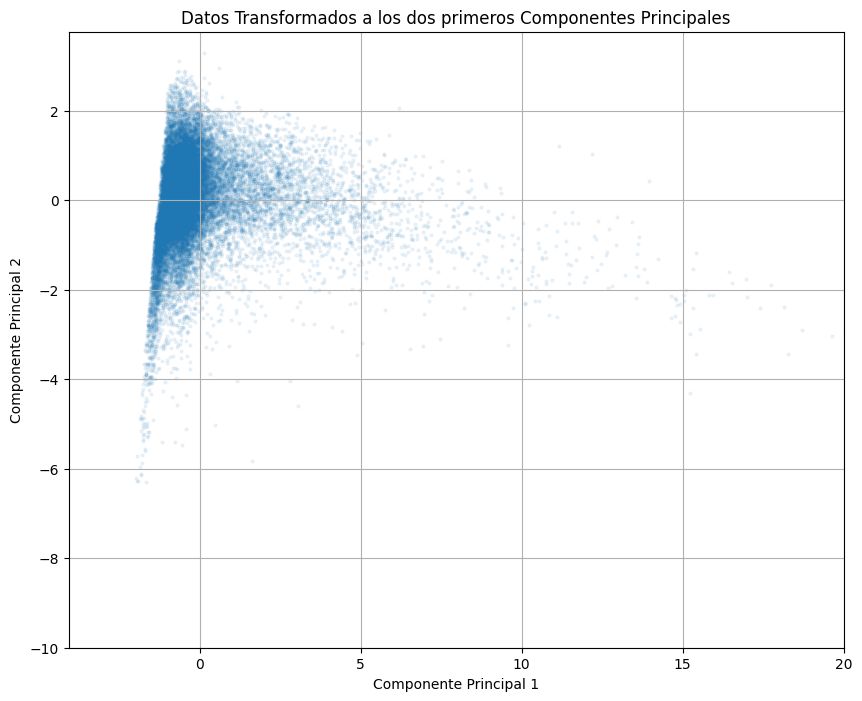

In [ ]:
# Transformar los datos a las nuevas componentes principales
x_pca = pca.transform(x_scaled)

# Graficar los dos primeros componentes principales
plt.figure(figsize=(10, 8))
plt.scatter(x_pca[:, 0], x_pca[:, 1], alpha=0.075, s=4)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Datos Transformados a los dos primeros Componentes Principales')
plt.xlim(right=20)
plt.ylim(bottom=-10)
plt.grid(True)
plt.show()

### 3.1 Visualización de Componentes Principales (Primeras 3)

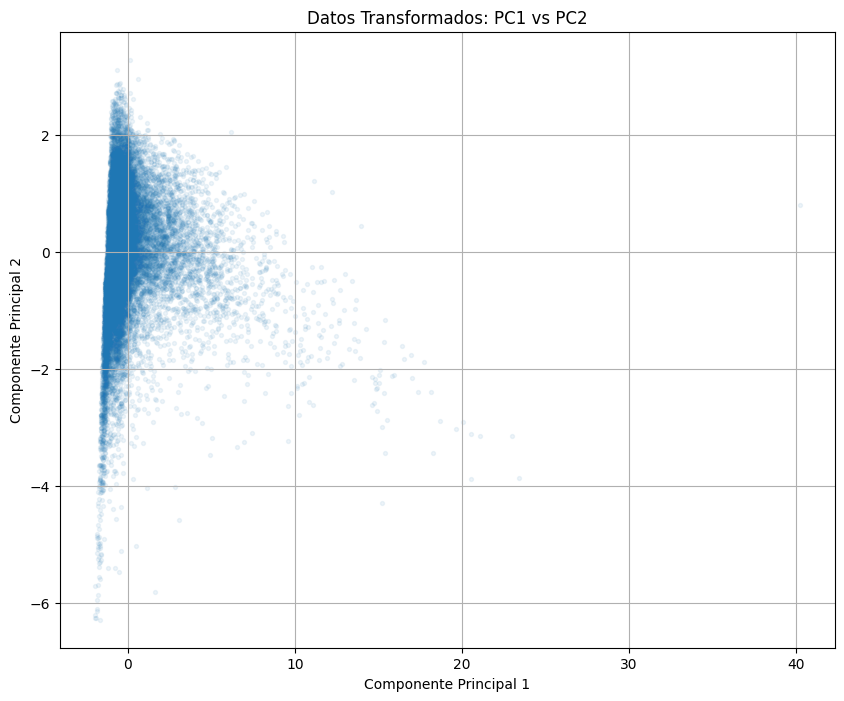

In [ ]:
import matplotlib.pyplot as plt

# Visualización de PC1 vs PC2
plt.figure(figsize=(10, 8))
plt.scatter(x_pca[:, 0], x_pca[:, 1], alpha=0.075, s=8)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Datos Transformados: PC1 vs PC2')
plt.grid(True)
plt.show()

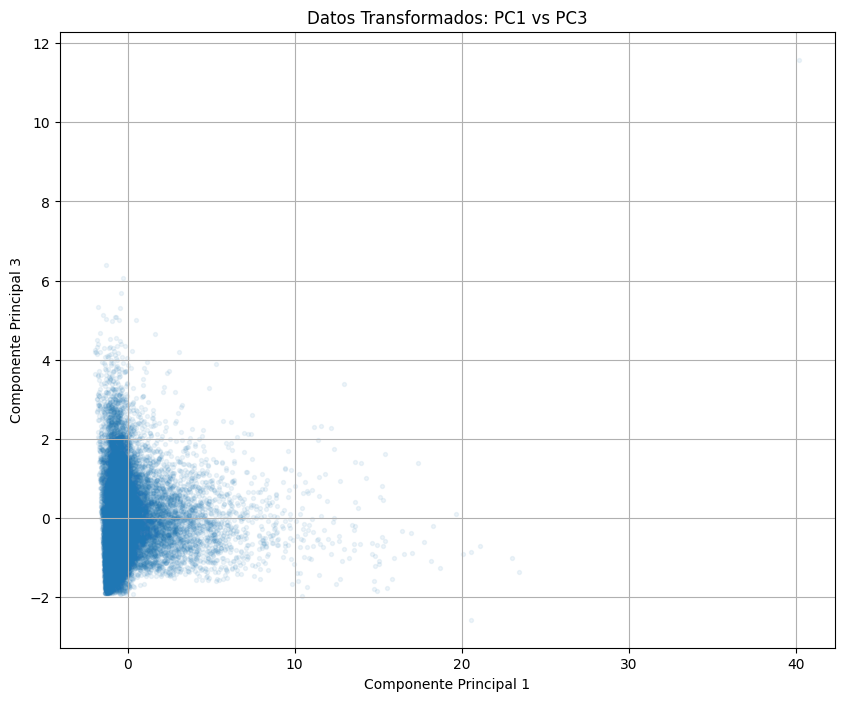

In [ ]:
import matplotlib.pyplot as plt

# Visualización de PC1 vs PC3
plt.figure(figsize=(10, 8))
plt.scatter(x_pca[:, 0], x_pca[:, 2], alpha=0.075, s=8)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 3')
plt.title('Datos Transformados: PC1 vs PC3')
plt.grid(True)
plt.show()

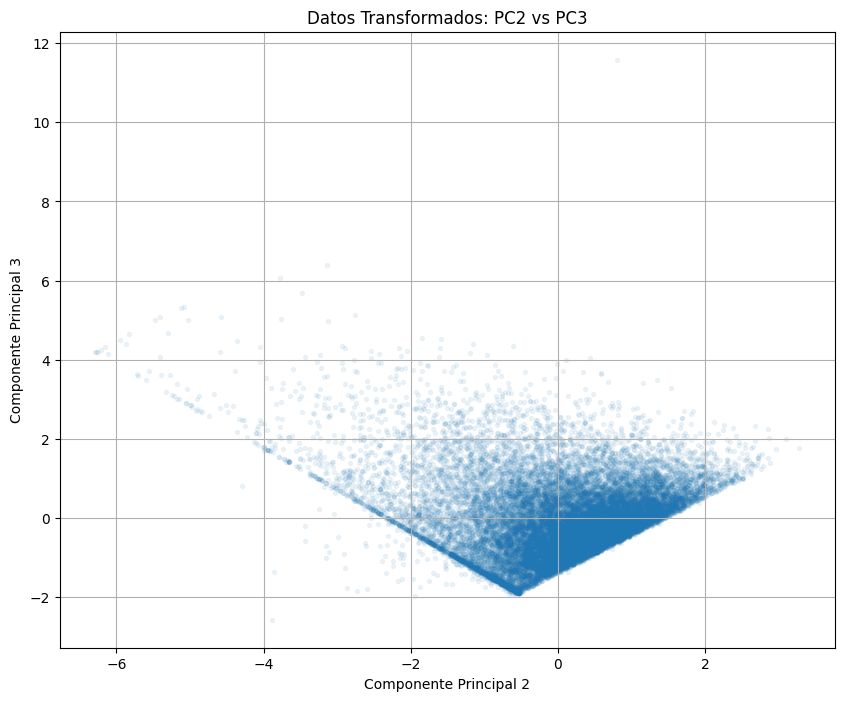

In [ ]:
import matplotlib.pyplot as plt

# Visualización de PC2 vs PC3
plt.figure(figsize=(10, 8))
plt.scatter(x_pca[:, 1], x_pca[:, 2], alpha=0.075, s=8)
plt.xlabel('Componente Principal 2')
plt.ylabel('Componente Principal 3')
plt.title('Datos Transformados: PC2 vs PC3')
plt.grid(True)
plt.show()

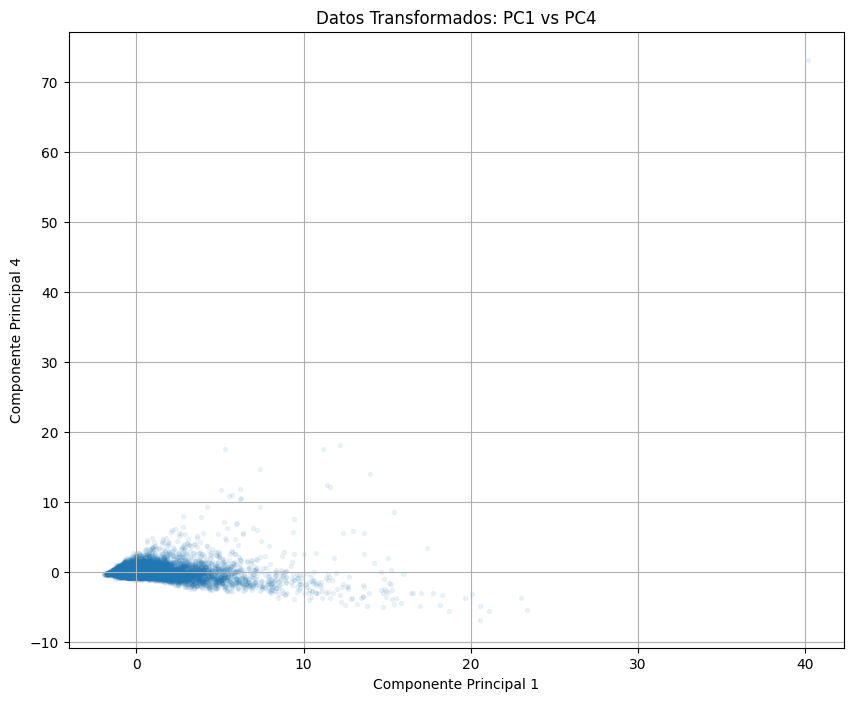

In [ ]:
plt.figure(figsize=(10, 8))
plt.scatter(x_pca[:, 0], x_pca[:, 3], alpha=0.075, s=8)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 4')
plt.title('Datos Transformados: PC1 vs PC4')
plt.grid(True)
plt.show()

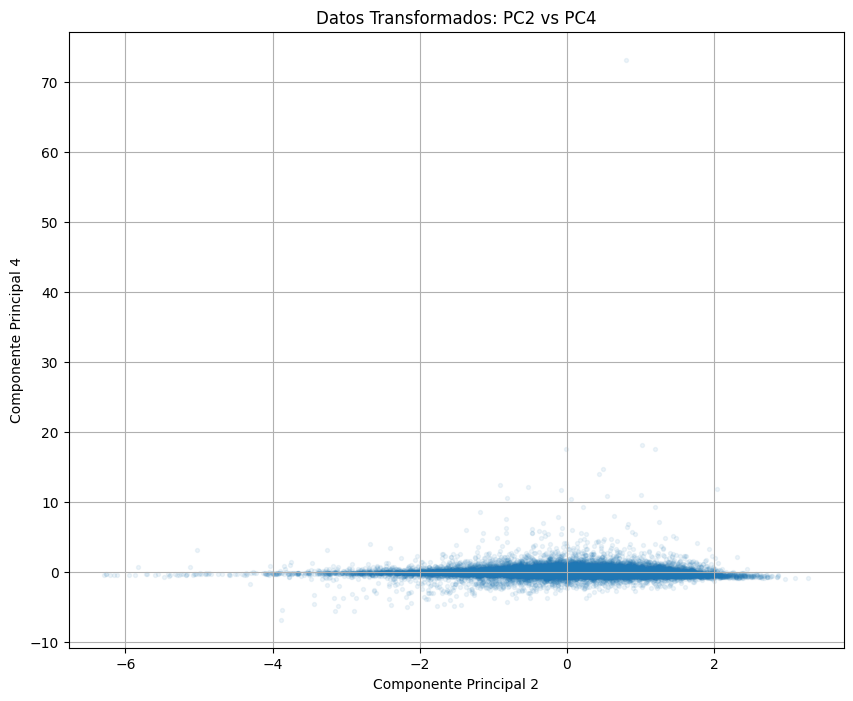

In [ ]:
plt.figure(figsize=(10, 8))
plt.scatter(x_pca[:, 1], x_pca[:, 3], alpha=0.075, s=8)
plt.xlabel('Componente Principal 2')
plt.ylabel('Componente Principal 4')
plt.title('Datos Transformados: PC2 vs PC4')
plt.grid(True)
plt.show()

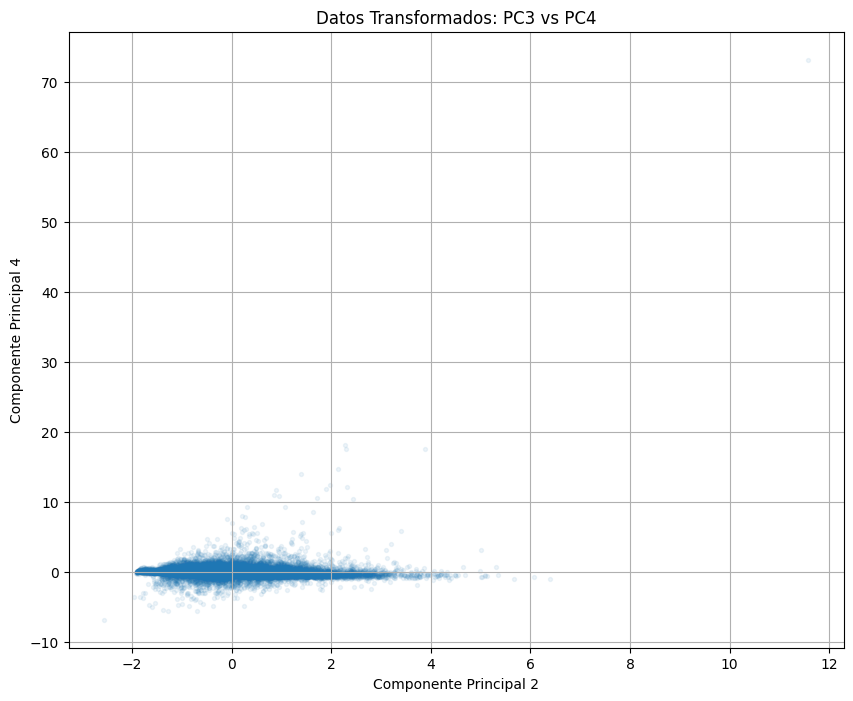

In [ ]:
plt.figure(figsize=(10, 8))
plt.scatter(x_pca[:, 2], x_pca[:, 3], alpha=0.075, s=8)
plt.xlabel('Componente Principal 2')
plt.ylabel('Componente Principal 4')
plt.title('Datos Transformados: PC3 vs PC4')
plt.grid(True)
plt.show()

## 4. Test de Esfericidad de Bartlett

El Test de Esfericidad de Bartlett se utiliza para verificar si las variables en un conjunto de datos están correlacionadas. Es un requisito previo para realizar un Análisis de Componentes Principales (PCA) o un Análisis Factorial Exploratorio (AFE). Si la hipótesis nula (las variables no están correlacionadas en la población) es rechazada (p-value < 0.05), entonces las variables están suficientemente correlacionadas para aplicar PCA o AFE.

In [ ]:
# Instalar la librería factor_analyzer si no está instalada
# Esta librería es necesaria para el Test de Esfericidad de Bartlett
!pip install factor_analyzer

In [ ]:
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity

# Realizar el Test de Esfericidad de Bartlett
# Los argumentos son el DataFrame de datos (x_scaled) y el número de observaciones (n_samples)
chi_square_value, p_value = calculate_bartlett_sphericity(x_scaled)

print(f"Valor Chi-cuadrado de Bartlett: {chi_square_value:.2f}")
print(f"P-value: {p_value:.3f}")

if p_value < 0.05:
    print("\nEl p-value es menor que 0.05, lo que indica que las variables están suficientemente correlacionadas para realizar un PCA.")
else:
    print("\nEl p-value es mayor que 0.05, lo que sugiere que las variables no están suficientemente correlacionadas.")